In [3]:
# %pip install librosa

# **Load Data and Zero Crossing Rate**

In [4]:
import librosa
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt, find_peaks
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import shutil
import os

In [5]:
# Import Libraries
import librosa
import librosa.display
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# Load sample audio and Zero Crossing Rate
signal, sr = librosa.load('../../data/train/healthy/a0007.wav')
signal_un, sr_un = librosa.load('../../data/train/unhealthy/a0008.wav')



/opt/anaconda3/envs/ml_env/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [7]:
# Function to compute ZCR per short frame (e.g., 20–30 ms) to capture temporal variations:

def zcr(rate, data):
  frame_size = int(0.02 * rate)  # 20 ms frame
  num_frames = len(data) // frame_size

  zcrs = []

  for i in range(num_frames):
      start = i * frame_size
      end = start + frame_size
      frame = data[start:end]
      signs = np.sign(frame)
      crossings = np.where(np.diff(signs))[0]
      zcr_frame = len(crossings) / frame_size
      zcrs.append(zcr_frame)

  # Average ZCR across all frames
  avg_zcr = np.mean(zcrs)
  print("Average Zero-Crossing Rate:", avg_zcr)

Average Zero-Crossing Rate: 0.0030865963884151525
Average Zero-Crossing Rate: 0.0034659673925436095


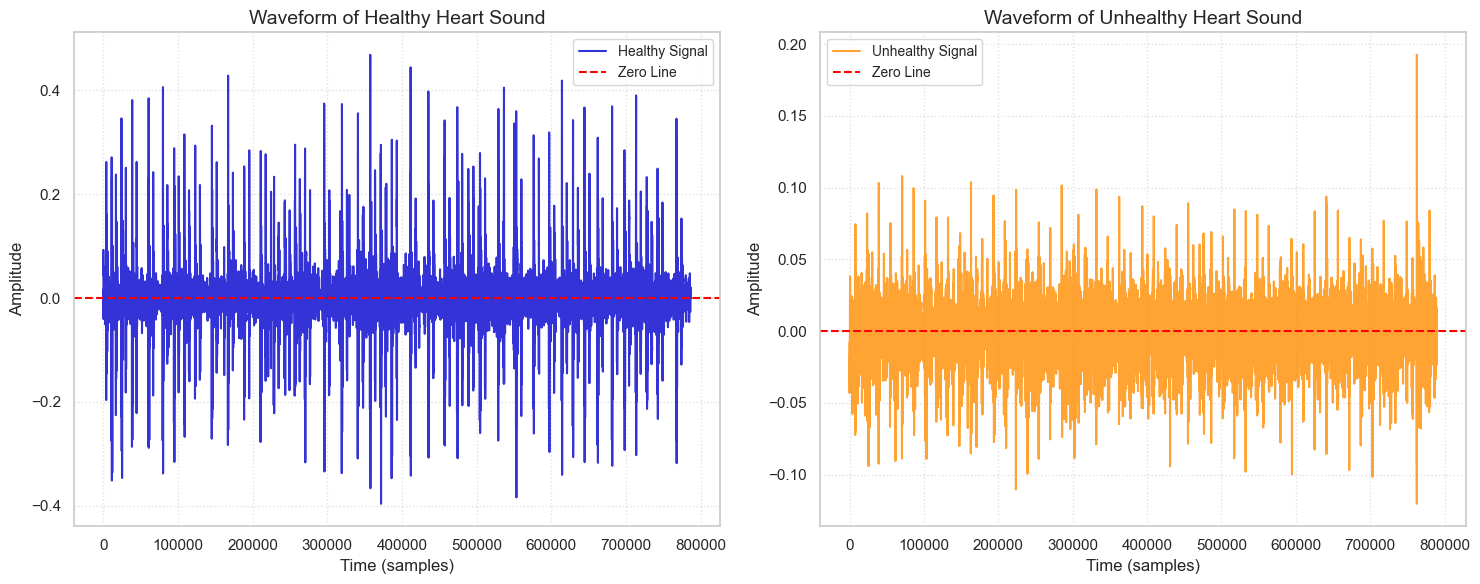

In [8]:
# Compute the sign of the samples
healty_signal = zcr(sr, signal)
unhealthy_signal = zcr(sr_un, signal_un)

import seaborn as sns

# Set seaborn style for better aesthetics
sns.set_theme(style="whitegrid")

plt.figure(figsize=(15, 6))

# Plot for Healthy Signal
plt.subplot(1, 2, 1) # 1 row, 2 columns, first plot
plt.plot(signal, label='Healthy Signal', color='mediumblue', alpha=0.8)
plt.axhline(0, color='red', linestyle='--', label='Zero Line', linewidth=1.5)
plt.title('Waveform of Healthy Heart Sound', fontsize=14)
plt.xlabel('Time (samples)', fontsize=12)
plt.ylabel('Amplitude', fontsize=12)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

# Plot for Unhealthy Signal
plt.subplot(1, 2, 2) # 1 row, 2 columns, second plot
plt.plot(signal_un, label='Unhealthy Signal', color='darkorange', alpha=0.8)
plt.axhline(0, color='red', linestyle='--', label='Zero Line', linewidth=1.5)
plt.title('Waveform of Unhealthy Heart Sound', fontsize=14)
plt.xlabel('Time (samples)', fontsize=12)
plt.ylabel('Amplitude', fontsize=12)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout() # Adjust layout to prevent overlapping titles/labels
plt.show()

# **Preprocessing**

In [9]:
# Bandpass filtering

def bandpass_filter(data, lowcut, highcut, fs):
    nyquist = 0.5 * fs
    low = lowcut / nyquist
    high = highcut / nyquist

    b, a = butter(4, [low, high], btype='band')
    filtered = filtfilt(b, a, data)

    return filtered

filtered_signal = bandpass_filter(signal, 20, 400, sr)

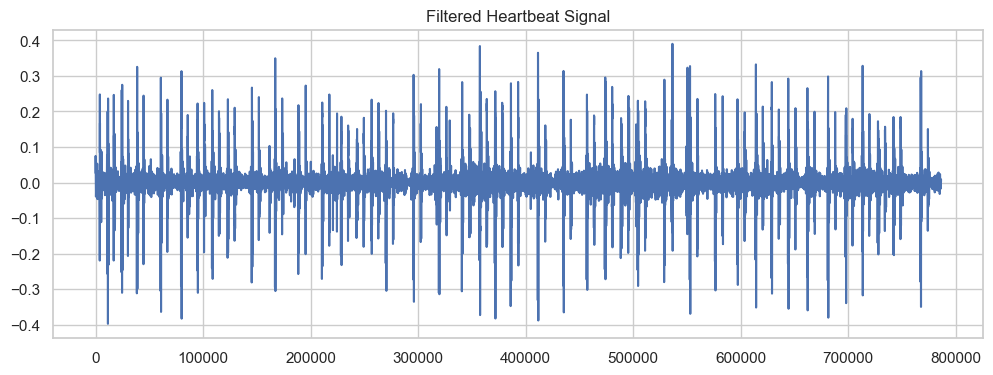

In [10]:
plt.figure(figsize=(12,4))
plt.plot(filtered_signal)
plt.title("Filtered Heartbeat Signal")
plt.show()

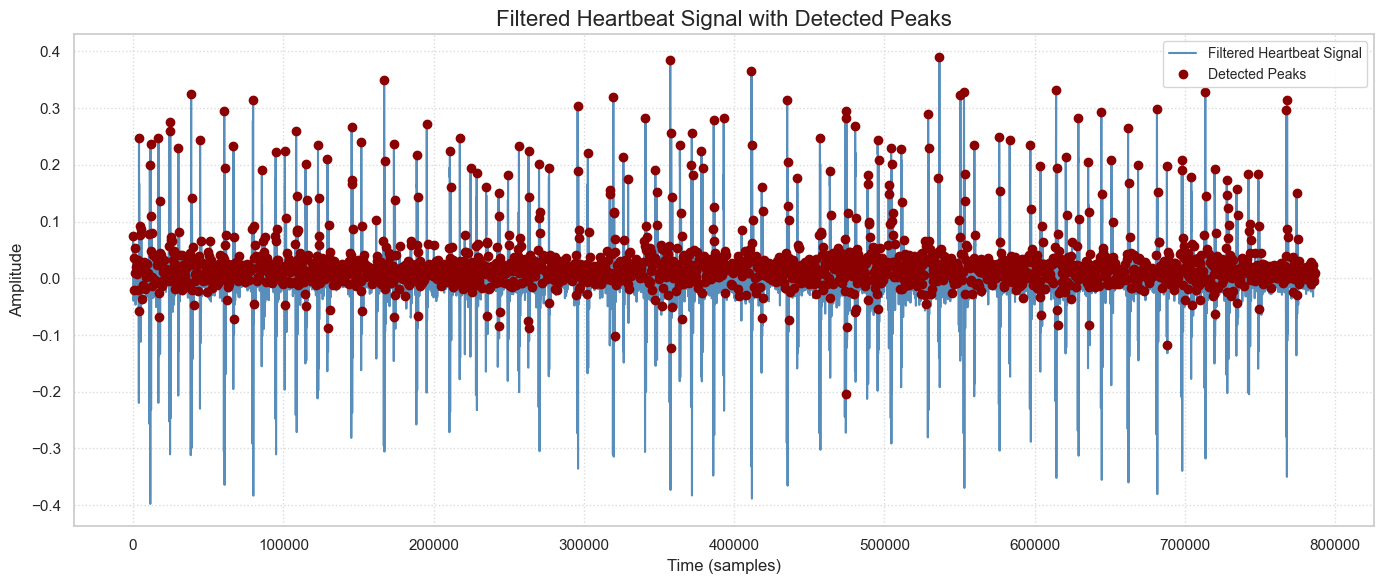

In [11]:
# Detect the heartbeat(high frequncies)
peaks, _ = find_peaks(filtered_signal, distance=200)

import seaborn as sns
sns.set_theme(style="whitegrid")

plt.figure(figsize=(14, 6))
plt.plot(filtered_signal, label='Filtered Heartbeat Signal', color='steelblue', alpha=0.9)
plt.plot(peaks, filtered_signal[peaks], "o", color='darkred', markersize=6, label='Detected Peaks')
plt.title('Filtered Heartbeat Signal with Detected Peaks', fontsize=16)
plt.xlabel('Time (samples)', fontsize=12)
plt.ylabel('Amplitude', fontsize=12)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

In [12]:
peaks, _ = find_peaks(filtered_signal, distance=200)
print("Peaks:", peaks[0])

import seaborn as sns
sns.set_theme(style="whitegrid")

# plt.figure(figsize=(14, 6))
# plt.plot(filtered_signal, label='Filtered Heartbeat Signal', color='steelblue', alpha=0.9)
# plt.plot(peaks, filtered_signal[0], "o", color='darkred', markersize=6, label='Detected Peaks')
# plt.title('Filtered Heartbeat Signal with Detected Peaks', fontsize=16)
# plt.xlabel('Time (samples)', fontsize=12)
# plt.ylabel('Amplitude', fontsize=12)
# plt.legend(fontsize=10)
# plt.grid(True, linestyle=':', alpha=0.7)
# plt.tight_layout()
# plt.show()

p = peaks[0]
window = int(0.3 * sr)
start = max(p - window//2, 0)
print("Start:", start)
end = min(p + window//2, len(filtered_signal))
print("End:", end)


Peaks: 27
Start: 0
End: 3334


In [13]:
beats = []

window = int(0.3 * sr)

for p in peaks:
    start = max(p - window//2, 0)
    end = min(p + window//2, len(filtered_signal))
    beats.append(filtered_signal[start:end])

In [14]:
beat = beats[0]

mfcc = librosa.feature.mfcc(y=beat, sr=sr, n_mfcc=13)
zcr = librosa.feature.zero_crossing_rate(beat)
centroid = librosa.feature.spectral_centroid(y=beat, sr=sr)

features = np.concatenate([
    np.mean(mfcc, axis=1),
    [np.mean(zcr)],
    [np.mean(centroid)]
])

print('mfcc', mfcc[:1])
print('zcr', zcr[:5])
print('centroid', centroid.shape)


mfcc [[-384.2587549  -450.1948465  -716.32727649 -712.69086895 -704.77841275
  -589.82473582 -431.90037167]]
zcr [[0.00146484 0.00292969 0.00390625 0.00341797 0.00439453 0.00341797
  0.00244141]]
centroid (1, 7)


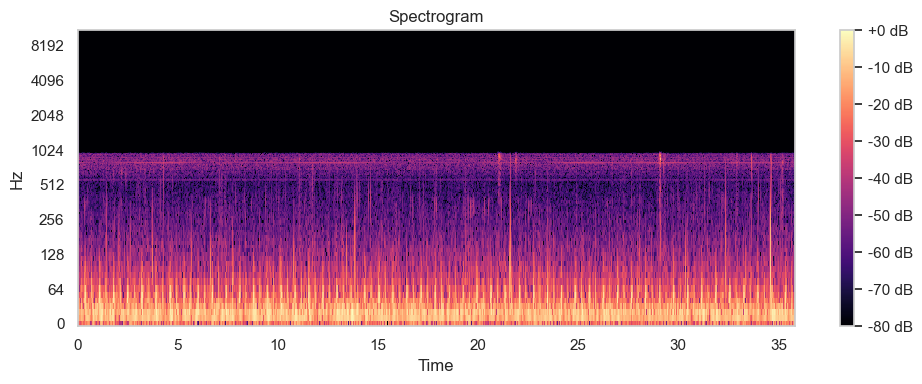

In [15]:
# Spectogram of the sample audio

# Compute spectrogram
S = librosa.stft(signal_un)
S_db = librosa.amplitude_to_db(abs(S), ref=np.max)

# Plot spectrogram
plt.figure(figsize=(10,4))
librosa.display.specshow(S_db, sr=sr, x_axis='time', y_axis='log')
plt.colorbar(format='%+2.0f dB')
plt.title("Spectrogram")
plt.tight_layout()
plt.show()

# **Load the files**

In [16]:
#
train_path = "./data/train"
val_path = "./data/val"

In [17]:
# Function to Load Dataset
# Change these paths to your Colab upload folder

def load_audio_files(base_path):
    audio_list = []
    labels = []
    for label_name, label_value in [("healthy", 0), ("unhealthy", 1)]:
        folder = os.path.join(base_path, label_name)
        for fname in os.listdir(folder):
            path = os.path.join(folder, fname)
            try:
                signal, sr = librosa.load(path, sr=None)
                audio_list.append((signal, sr))
                labels.append(label_value)
            except:
                print(f"Could not load {path}")
    return audio_list, np.array(labels)

train_audio, y_train = load_audio_files(train_path)
val_audio, y_val = load_audio_files(val_path)

print(f"Train samples: {len(train_audio)}, Validation samples: {len(val_audio)}")

Train samples: 3240, Validation samples: 301


# **Implementation with Random Forest**

In [18]:
# Detect Peaks and Segment Heartbeat

def segment_beats(signal, sr, lowcut=20, highcut=400, window_sec=0.3):
    # Band-pass filter
    filtered = bandpass_filter(signal, lowcut, highcut, sr)

    # Detect peaks
    peaks, _ = find_peaks(filtered, distance=int(0.3*sr))

    # Segment beats
    window = int(window_sec * sr)
    beats = []
    for p in peaks:
        start = max(p - window//2, 0)
        end = min(p + window//2, len(filtered))
        beats.append(filtered[start:end])

    return beats

In [19]:
# Feature Extraction
def extract_features(beat, sr):
    n_fft = min(2048, len(beat))

    mfcc = librosa.feature.mfcc(y=beat, sr=sr, n_mfcc=13, n_fft=n_fft)
    mfcc_mean = np.mean(mfcc, axis=1)

    zcr = np.mean(librosa.feature.zero_crossing_rate(beat))
    centroid = np.mean(librosa.feature.spectral_centroid(y=beat, sr=sr, n_fft=n_fft))

    return np.concatenate([mfcc_mean, [zcr, centroid]])

In [20]:
# Build Dataset
def build_feature_dataset(audio_list, labels):
    X = []
    y = []
    for i, (signal, sr) in enumerate(audio_list):
        beats = segment_beats(signal, sr)
        for beat in beats:
            features = extract_features(beat, sr)
            X.append(features)
            y.append(labels[i])
    return np.array(X), np.array(y)

X_train, y_train_beats = build_feature_dataset(train_audio, y_train)
X_val, y_val_beats = build_feature_dataset(val_audio, y_val)

print(f"Training beats: {X_train.shape[0]}, Validation beats: {X_val.shape[0]}")

Training beats: 188525, Validation beats: 16241


In [21]:
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42, 
    max_depth=10,            # Limits how deep trees can grow
    min_samples_split=5,     # Requires more samples to split a node
    min_samples_leaf=4       # Forces larger terminal leaf nodes
)
model.fit(X_train, y_train_beats)

,n_estimators,100
,criterion,'gini'
,max_depth,10
,min_samples_split,5
,min_samples_leaf,4
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


Classification Report:
              precision    recall  f1-score   support

           0       0.68      0.79      0.73      8054
           1       0.76      0.64      0.69      8187

    accuracy                           0.71     16241
   macro avg       0.72      0.71      0.71     16241
weighted avg       0.72      0.71      0.71     16241



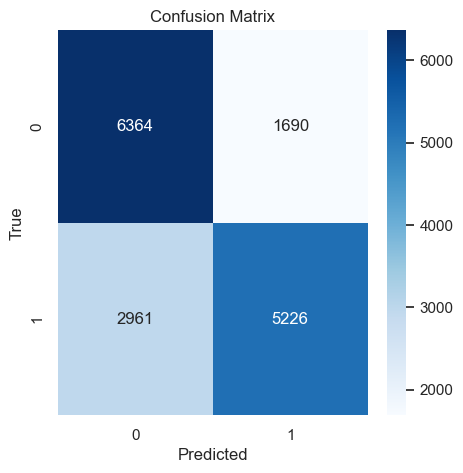

In [22]:
y_pred = model.predict(X_val)

print("Classification Report:")
print(classification_report(y_val_beats, y_pred))

# Confusion matrix
cm = confusion_matrix(y_val_beats, y_pred)
plt.figure(figsize=(5,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()

# **Implementation With CNN**

In [23]:
# Feature extraction or Converting Beat to MFCC by increasing the MFCC count to 40
def beat_to_mfcc_image(beat, sr, n_mfcc=40, max_len=50):

    n_fft = min(2048, len(beat))

    mfcc = librosa.feature.mfcc(
        y=beat,
        sr=sr,
        n_mfcc=n_mfcc,
        n_fft=n_fft
    )

    # Normalize
    mfcc = (mfcc - np.min(mfcc)) / (np.max(mfcc) - np.min(mfcc) + 1e-6)

    # Pad or truncate to fixed length
    if mfcc.shape[1] < max_len:
        pad_width = max_len - mfcc.shape[1]
        mfcc = np.pad(mfcc, pad_width=((0,0),(0,pad_width)), mode='constant')
    else:
        mfcc = mfcc[:, :max_len]

    return mfcc

In [24]:
# Build Dataset for CNN
X_train_cnn = []
y_train_cnn = []

for i, (signal, sr) in enumerate(train_audio):

    beats = segment_beats(signal, sr)

    for beat in beats:

        mfcc_img = beat_to_mfcc_image(beat, sr)

        X_train_cnn.append(mfcc_img)
        y_train_cnn.append(y_train[i])


X_train_cnn = np.array(X_train_cnn)
X_train_cnn = X_train_cnn[..., np.newaxis]
y_train_cnn = np.array(y_train_cnn)

print(X_train_cnn.shape)


X_val_cnn = []
y_val_cnn = []

for i, (signal, sr) in enumerate(val_audio):

    beats = segment_beats(signal, sr)

    for beat in beats:

        mfcc_img = beat_to_mfcc_image(beat, sr)

        X_val_cnn.append(mfcc_img)
        y_val_cnn.append(y_val[i])


X_val_cnn = np.array(X_val_cnn)
X_val_cnn = X_val_cnn[..., np.newaxis]
y_val_cnn = np.array(y_val_cnn)

print(X_val_cnn.shape)

(188525, 40, 50, 1)
(16241, 40, 50, 1)


In [25]:
X_train_cnn.shape

(188525, 40, 50, 1)

In [26]:
# Compute Class Weight
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.unique(y_train_cnn)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_cnn
)

class_weights = dict(zip(classes, weights))

print(class_weights)


{0: 0.6512494731969518, 1: 2.1528983190206468}


In [27]:
# Improved Feature Extraction
import librosa
import numpy as np

def beat_to_feature_map(beat, sr, max_len=50):

    n_fft = min(2048, len(beat))

    # MFCC
    mfcc = librosa.feature.mfcc(y=beat, sr=sr, n_mfcc=40, n_fft=n_fft)

    # Spectral centroid
    centroid = librosa.feature.spectral_centroid(y=beat, sr=sr, n_fft=n_fft)

    # Zero crossing rate
    zcr = librosa.feature.zero_crossing_rate(beat)

    # Chroma
    chroma = librosa.feature.chroma_stft(y=beat, sr=sr, n_fft=n_fft)

    # Stack features
    feature_map = np.vstack([mfcc, centroid, zcr, chroma])

    # Normalize
    feature_map = (feature_map - np.min(feature_map)) / (np.max(feature_map) - np.min(feature_map) + 1e-6)

    # Pad or truncate time dimension
    if feature_map.shape[1] < max_len:
        pad = max_len - feature_map.shape[1]
        feature_map = np.pad(feature_map, ((0,0),(0,pad)), mode='constant')
    else:
        feature_map = feature_map[:, :max_len]

    return feature_map

In [28]:
X_train_cnn = []
y_train_cnn = []

for i, (signal, sr) in enumerate(train_audio):

    beats = segment_beats(signal, sr)

    beats = beats[:20]   # limit to avoid huge dataset

    for beat in beats:

        feature_map = beat_to_feature_map(beat, sr)

        X_train_cnn.append(feature_map)
        y_train_cnn.append(y_train[i])

X_train_cnn = np.array(X_train_cnn)
X_train_cnn = X_train_cnn[..., np.newaxis]

y_train_cnn = np.array(y_train_cnn)

print(X_train_cnn.shape)

/opt/anaconda3/envs/ml_env/lib/python3.10/site-packages/librosa/core/pitch.py:103: UserWarning: Trying to estimate tuning from empty frequency set.
  return pitch_tuning(


(64597, 54, 50, 1)


In [29]:
# Fix the model architecture for new input shape
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, Flatten, Dense, Dropout, MaxPooling1D
from tensorflow.keras.optimizers import Adam

# input_shape = X_train_cnn.shape[1:]  # (54, 50, 1)

model = Sequential([

    Conv1D(
        filters=32,
        kernel_size=3,
        activation='relu',
        input_shape=(54,50)
    ),

    MaxPooling1D(pool_size=2),

    Conv1D(64, 5, activation='relu'),
    MaxPooling1D(2),

    Conv1D(128, 5, activation='relu'),
    MaxPooling1D(2),

    Flatten(),

    Dense(128, activation='relu'),
    Dropout(0.5),

    Dense(5, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

/opt/anaconda3/envs/ml_env/lib/python3.10/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
2026-06-06 17:59:49.476050: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M2 Pro
2026-06-06 17:59:49.476090: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2026-06-06 17:59:49.476094: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.92 GB
2026-06-06 17:59:49.476149: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-06-06 17:59:49.476167: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_facto

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 52, 32)         │         4,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 26, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 22, 64)         │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 11, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 7, 128)         │        41,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_2 (MaxPooling1D)  │ (None, 3, 128)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 384)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        49,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 106,149 (414.64 KB)

 Trainable params: 106,149 (414.64 KB)

 Non-trainable params: 0 (0.00 B)

In [30]:
# Create validation dataset with new features
X_val_cnn = []
y_val_cnn = []

for i, (signal, sr) in enumerate(val_audio):
    beats = segment_beats(signal, sr)
    beats = beats[:20]   # limit to match training
    
    for beat in beats:
        feature_map = beat_to_feature_map(beat, sr)
        X_val_cnn.append(feature_map)
        y_val_cnn.append(y_val[i])

X_val_cnn = np.array(X_val_cnn)
X_val_cnn = X_val_cnn[..., np.newaxis]
y_val_cnn = np.array(y_val_cnn)

print(X_val_cnn.shape)


/opt/anaconda3/envs/ml_env/lib/python3.10/site-packages/librosa/core/pitch.py:103: UserWarning: Trying to estimate tuning from empty frequency set.
  return pitch_tuning(


(5961, 54, 50, 1)


In [31]:
# Train the corrected model
history = model.fit(
    X_train_cnn,
    y_train_cnn,
    validation_data=(X_val_cnn, y_val_cnn),
    epochs=100,
    batch_size=32
)


Epoch 1/100


2026-06-06 18:00:08.434288: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


2019/2019 ━━━━━━━━━━━━━━━━━━━━ 39s 17ms/step - accuracy: 0.7938 - loss: 0.5228 - val_accuracy: 0.4986 - val_loss: 0.8786
Epoch 2/100
2019/2019 ━━━━━━━━━━━━━━━━━━━━ 33s 16ms/step - accuracy: 0.7950 - loss: 0.4913 - val_accuracy: 0.4986 - val_loss: 0.7483
Epoch 3/100
2019/2019 ━━━━━━━━━━━━━━━━━━━━ 31s 15ms/step - accuracy: 0.7911 - loss: 0.4587 - val_accuracy: 0.4987 - val_loss: 0.8097
Epoch 4/100
2019/2019 ━━━━━━━━━━━━━━━━━━━━ 31s 15ms/step - accuracy: 0.7885 - loss: 0.4487 - val_accuracy: 0.4987 - val_loss: 0.8218
Epoch 5/100
2019/2019 ━━━━━━━━━━━━━━━━━━━━ 31s 15ms/step - accuracy: 0.7873 - loss: 0.4382 - val_accuracy: 0.4994 - val_loss: 0.8320
Epoch 6/100
2019/2019 ━━━━━━━━━━━━━━━━━━━━ 31s 15ms/step - accuracy: 0.7844 - loss: 0.4259 - val_accuracy: 0.5197 - val_loss: 0.7642
Epoch 7/100
2019/2019 ━━━━━━━━━━━━━━━━━━━━ 31s 15ms/step - accuracy: 0.7828 - loss: 0.4178 - val_accuracy: 0.5595 - val_loss: 0.6680
Epoch 8/100
2019/2019 ━━━━━━━━━━━━━━━━━━━━ 33s 16ms/step - accuracy: 0.7851 - los

187/187 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


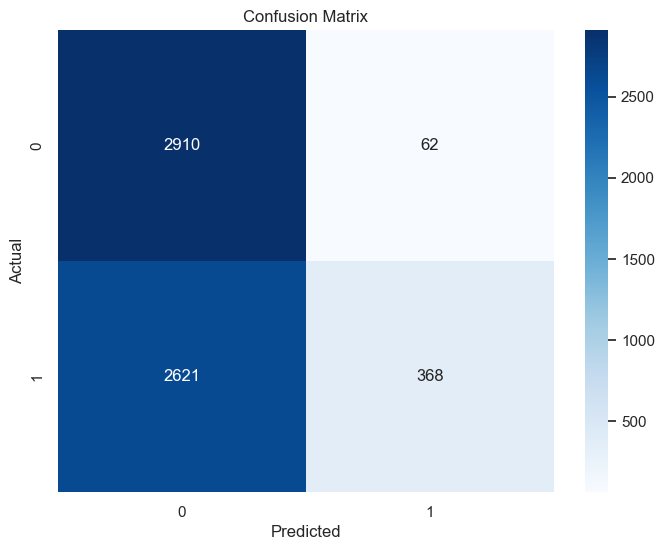

              precision    recall  f1-score   support

           0       0.53      0.98      0.68      2972
           1       0.86      0.12      0.22      2989

    accuracy                           0.55      5961
   macro avg       0.69      0.55      0.45      5961
weighted avg       0.69      0.55      0.45      5961



In [32]:
# Predict
y_pred_probs = model.predict(X_val_cnn)
y_pred = np.argmax(y_pred_probs, axis=1)

# Confusion matrix
cm = confusion_matrix(y_val_cnn, y_pred)

# Plot
plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

# Report
print(classification_report(y_val_cnn, y_pred))

In [33]:
# Check the class imbalance
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.unique(y_train_cnn)

print("Class distribution in training set:")
print(np.bincount(y_train_cnn))

weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y_train_cnn
)

class_weights = dict(zip(classes, weights))

print(class_weights)

Class distribution in training set:
[51353 13244]
{0: 0.628950596849259, 1: 2.4387269707037147}


In [34]:
history = model.fit(
    X_train_cnn,
    y_train_cnn,
    validation_data=(X_val_cnn, y_val_cnn),
    epochs=50,
    batch_size=32,
    class_weight=class_weights
)


Epoch 1/50
2019/2019 ━━━━━━━━━━━━━━━━━━━━ 33s 16ms/step - accuracy: 0.6846 - loss: 0.9134 - val_accuracy: 0.6600 - val_loss: 0.8576
Epoch 2/50
2019/2019 ━━━━━━━━━━━━━━━━━━━━ 32s 16ms/step - accuracy: 0.6864 - loss: 0.9045 - val_accuracy: 0.6761 - val_loss: 0.8833
Epoch 3/50
2019/2019 ━━━━━━━━━━━━━━━━━━━━ 31s 15ms/step - accuracy: 0.6892 - loss: 0.9008 - val_accuracy: 0.5935 - val_loss: 1.3165
Epoch 4/50
2019/2019 ━━━━━━━━━━━━━━━━━━━━ 31s 16ms/step - accuracy: 0.6896 - loss: 0.8660 - val_accuracy: 0.6710 - val_loss: 0.7218
Epoch 5/50
2019/2019 ━━━━━━━━━━━━━━━━━━━━ 31s 15ms/step - accuracy: 0.6852 - loss: 0.8856 - val_accuracy: 0.6715 - val_loss: 0.9588
Epoch 6/50
2019/2019 ━━━━━━━━━━━━━━━━━━━━ 31s 15ms/step - accuracy: 0.6917 - loss: 0.8398 - val_accuracy: 0.6217 - val_loss: 1.3578
Epoch 7/50
2019/2019 ━━━━━━━━━━━━━━━━━━━━ 31s 15ms/step - accuracy: 0.6885 - loss: 0.8857 - val_accuracy: 0.6746 - val_loss: 0.8069
Epoch 8/50
2019/2019 ━━━━━━━━━━━━━━━━━━━━ 31s 15ms/step - accuracy: 0.6924 -

187/187 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


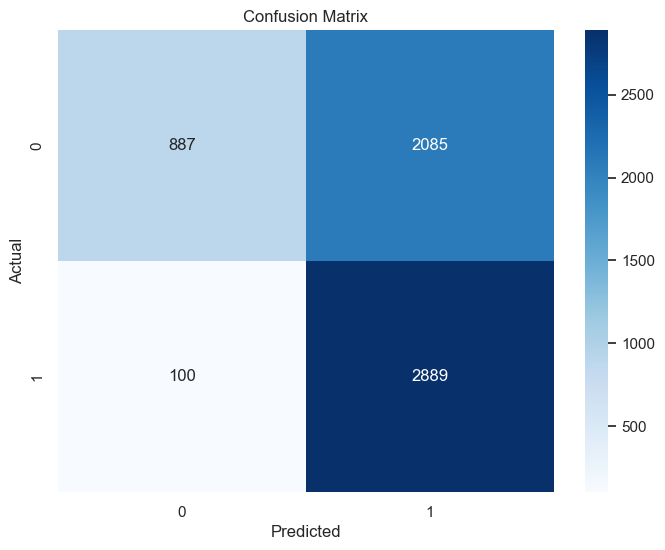

              precision    recall  f1-score   support

           0       0.90      0.30      0.45      2972
           1       0.58      0.97      0.73      2989

    accuracy                           0.63      5961
   macro avg       0.74      0.63      0.59      5961
weighted avg       0.74      0.63      0.59      5961



In [39]:
# Predict
y_pred_probs = model.predict(X_val_cnn)
y_pred = np.argmax(y_pred_probs, axis=1)

# Confusion matrix
cm = confusion_matrix(y_val_cnn, y_pred)

# Plot
plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

# Report
print(classification_report(y_val_cnn, y_pred))
